# 03 — Interpretation and targeting

Interpretation focuses on predictive associations, calibration and campaign-style ranking metrics. No causal claims are made.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))
import pandas as pd
import matplotlib.pyplot as plt
from telco_churn.data import load_splits
from telco_churn.features import add_active_product_count, split_xy
frames = load_splits(ROOT / 'data' / 'synthetic')


In [2]:
coef = pd.read_csv(ROOT / 'reports' / 'metrics' / 'logistic_coefficients.csv')
coef[['feature','coefficient','odds_ratio_per_model_unit']].head(12)

,feature,coefficient,odds_ratio_per_model_unit
0,categorical__Contract_Two Year,-1.301538,0.272113
1,categorical__Contract_One Year,-0.839174,0.432067
2,numeric__Tenure in Months,-0.516261,0.596748
3,numeric__Preperiod Satisfaction Score,-0.488442,0.613581
4,numeric__Monthly Charge,0.475860,1.609397
5,categorical__Internet Type_Fiber Optic,0.295755,1.344140
6,categorical__Payment Method_Mailed Check,0.253503,1.288531
7,numeric__Number of Referrals,-0.190100,0.826877
8,categorical__Internet Type_None,-0.168745,0.844724
9,numeric__Premium Tech Support,-0.129837,0.878239


For standardized numeric features, the exponentiated coefficient corresponds to a one-standard-deviation change on the model scale. Categorical terms are relative to the dropped reference category.

In [3]:
topk = pd.read_csv(ROOT / 'reports' / 'metrics' / 'test_top_k_metrics.csv')
topk

,top_fraction,customers_targeted,churners_captured,precision,recall,lift
0,0.05,71,46,0.647887,0.116456,2.311071
1,0.10,141,91,0.645390,0.230380,2.302164
2,0.20,282,166,0.588652,0.420253,2.099776
3,0.30,423,223,0.527187,0.564557,1.880522


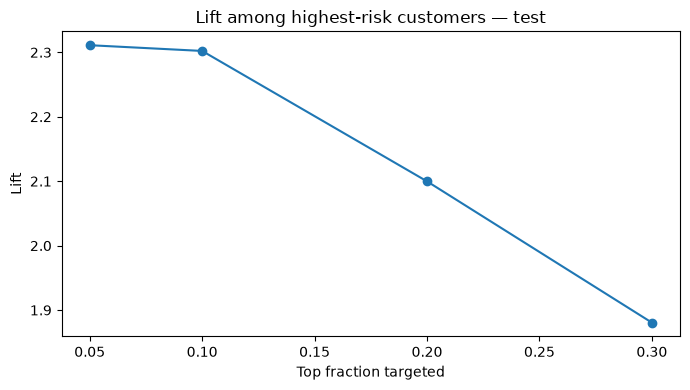

In [4]:
ax = topk.plot(x='top_fraction', y='lift', marker='o', legend=False, figsize=(7,4))
ax.set(title='Lift among highest-risk customers — test', xlabel='Top fraction targeted', ylabel='Lift')
plt.tight_layout(); plt.show()

In [5]:
subgroups = pd.read_csv(ROOT / 'reports' / 'metrics' / 'test_subgroup_diagnostics.csv')
subgroups

,attribute,group,n,prevalence,precision,recall,false_positive_rate,predicted_positive_rate,roc_auc
0,Gender,Female,730,0.260274,0.497561,0.536842,0.190741,0.280822,0.758821
1,Gender,Male,679,0.301915,0.568720,0.585366,0.191983,0.310751,0.775198
2,Age Band,18-29,203,0.310345,0.541667,0.619048,0.235714,0.354680,0.755215
3,Age Band,30-44,425,0.261176,0.510791,0.639640,0.216561,0.327059,0.784071
4,Age Band,45-64,602,0.265781,0.525974,0.506250,0.165158,0.255814,0.762429
5,Age Band,65+,179,0.340782,0.607843,0.508197,0.169492,0.284916,0.771048


Subgroup tables are diagnostics, not a fairness certification. They are included to make differences visible and to discourage deploying a model without governance and representative real-world validation.